# Q2.

In [3]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

X = np.array([[1, 2],[0,6],[1,0],[0,5],[1,7]])
y = np.array([[1],[2],[3],[4],[5]])

## Using linear regression
**add bias 1's column for linear regression**

In [4]:
Xb = np.concatenate((np.ones((X.shape[0], 1)), X), axis=1)
print(Xb)

[[1. 1. 2.]
 [1. 0. 6.]
 [1. 1. 0.]
 [1. 0. 5.]
 [1. 1. 7.]]


**tall X, left inverse**

In [5]:
wL = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y
print(wL)

[[1.13207547]
 [0.8490566 ]
 [0.33962264]]


## Using polynomial regression
**construct polynormial features**

In [7]:
poly = PolynomialFeatures(3)
P = poly.fit_transform(X)
print(P)

[[  1.   1.   2.   1.   2.   4.   1.   2.   4.   8.]
 [  1.   0.   6.   0.   0.  36.   0.   0.   0. 216.]
 [  1.   1.   0.   1.   0.   0.   1.   0.   0.   0.]
 [  1.   0.   5.   0.   0.  25.   0.   0.   0. 125.]
 [  1.   1.   7.   1.   7.  49.   1.   7.  49. 343.]]


In [8]:
print(poly.get_feature_names_out())

['1' 'x0' 'x1' 'x0^2' 'x0 x1' 'x1^2' 'x0^3' 'x0^2 x1' 'x0 x1^2' 'x1^3']


**tall P, left inverse**

In [9]:
wP = np.linalg.inv(P.T @ P) @ P.T @ y
print(wP)

LinAlgError: Singular matrix

**reshape 9 to a column vector to use for prediction**

Details about `reshape` can be found [here](#about-reshape)

In [7]:
np.array(9).reshape(-1,1)

array([[9]])

In [10]:
# X_pred = np.array(9).reshape(-1,1)
X_pred = np.array([[1,3]])
P_pred = poly.fit_transform(X_pred)
print(P_pred)

poly_pred = P_pred @ wP
print(poly_pred)

[[ 1.  1.  3.  1.  3.  9.  1.  3.  9. 27.]]


NameError: name 'wP' is not defined

In [11]:
Xb_pred = np.concatenate((np.ones_like(X_pred),X_pred), axis=1)
linear_pred = Xb_pred@wL
print(linear_pred)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)

## Draw the plot to show difference

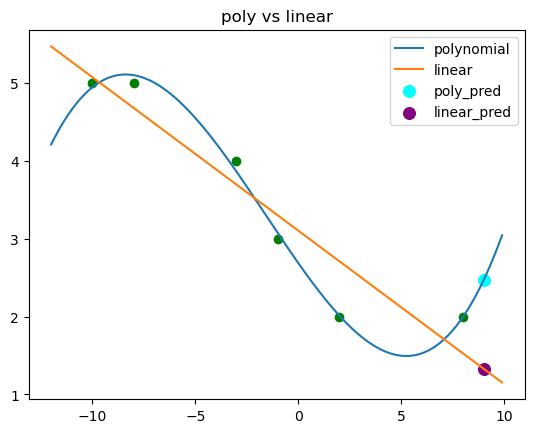

In [13]:
xx = np.arange(X.min()-2, X.max()+2, 0.1).reshape(-1,1)
poly_xx = poly.fit_transform(xx)
linear_xx = np.concatenate((np.ones_like(xx),xx), axis=1)

yyP = poly_xx@wP
yyL = linear_xx@wL

plt.scatter(X,y, color='g')
plt.plot(xx, yyP, label='polynomial')
plt.plot(xx, yyL, label='linear')

plt.scatter(X_pred, poly_pred, label='poly_pred', color='cyan', s=70)
plt.scatter(X_pred, linear_pred, label='linear_pred', color='purple', s=70)

plt.title('poly vs linear')
plt.legend()
plt.show()

# Q3.

In [14]:
X = np.array([[1, 0, 1],
              [1, -1, 1]])
poly = PolynomialFeatures(3)
P = poly.fit_transform(X)
print(P)

[[ 1.  1.  0.  1.  1.  0.  1.  0.  0.  1.  1.  0.  1.  0.  0.  1.  0.  0.
   0.  1.]
 [ 1.  1. -1.  1.  1. -1.  1.  1. -1.  1.  1. -1.  1.  1. -1.  1. -1.  1.
  -1.  1.]]


In [15]:
print(poly.get_feature_names_out())

['1' 'x0' 'x1' 'x2' 'x0^2' 'x0 x1' 'x0 x2' 'x1^2' 'x1 x2' 'x2^2' 'x0^3'
 'x0^2 x1' 'x0^2 x2' 'x0 x1^2' 'x0 x1 x2' 'x0 x2^2' 'x1^3' 'x1^2 x2'
 'x1 x2^2' 'x2^3']


## dual form without lambda (right inverse)

In [17]:
y = np.array([[0],
              [1]])
w_dual = P.T @ np.linalg.inv(P@P.T) @ y
print(np.linalg.matrix_rank(P@P.T))
print(w_dual)

2
[[ 0. ]
 [ 0. ]
 [-0.1]
 [ 0. ]
 [ 0. ]
 [-0.1]
 [ 0. ]
 [ 0.1]
 [-0.1]
 [ 0. ]
 [ 0. ]
 [-0.1]
 [ 0. ]
 [ 0.1]
 [-0.1]
 [ 0. ]
 [-0.1]
 [ 0.1]
 [-0.1]
 [ 0. ]]


## primal ridge form (with lambda)

In [18]:
(P.T @ P).shape

(20, 20)

In [19]:
P.shape

(2, 20)

In [20]:
np.identity(P.shape[1])

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.

In [21]:
lmd = 1e-4   # hyperparameter for regularization
w_ridge_primal = np.linalg.inv(P.T@P + lmd*np.identity(P.shape[1])) @ P.T @y
print(w_ridge_primal)

[[ 9.99977146e-07]
 [ 9.99968393e-07]
 [-9.99980001e-02]
 [ 9.99972258e-07]
 [ 9.99974304e-07]
 [-9.99980001e-02]
 [ 9.99965096e-07]
 [ 9.99980000e-02]
 [-9.99980001e-02]
 [ 9.99970325e-07]
 [ 9.99969416e-07]
 [-9.99980000e-02]
 [ 9.99968506e-07]
 [ 9.99980001e-02]
 [-9.99980001e-02]
 [ 9.99969302e-07]
 [-9.99980000e-02]
 [ 9.99980000e-02]
 [-9.99980000e-02]
 [ 9.99967597e-07]]


# Q4.

In [22]:
X = np.array([[1,-1], 
              [1,0], 
              [1,0.5], 
              [1,0.3], 
              [1,0.8]])
y = np.array([[1], [1], [-1], [1], [-1]])
## Linear regression for classification
w = np.linalg.inv(X.T @ X) @ X.T @ y
print(w)

[[ 0.33333333]
 [-1.11111111]]


In [23]:
Xt = np.array([[1,-0.1], 
               [1,0.4]])
y_predict = Xt @ w
print(y_predict)

[[ 0.44444444]
 [-0.11111111]]


In [24]:
y_class_predict = np.sign(y_predict)
print(y_class_predict)

[[ 1.]
 [-1.]]


# Q5.

In [27]:
X = np.array([[-1], 
              [0], 
              [0.5], 
              [0.3], 
              [0.8]])
Xb = np.concatenate((np.ones_like(X),X), axis=1)
y = np.array([1,1,2,3,2]).reshape(-1,1)

## Use `OneHotEncoder` to generate y for training

In [29]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False)
Y = ohe.fit_transform(y)
print(Y)

[[1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]


In [30]:
## Linear regression for classification 
W = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ Y
print(W)

[[ 0.47798742  0.33333333  0.18867925]
 [-0.64989518  0.55555556  0.09433962]]


## Make prediction using trained model, convert one-hot encoded label to class

In [31]:
Xt = np.array([[-0.1], 
               [0.4]])
Xtb = np.concatenate((np.ones_like(Xt),Xt), axis=1)
y_predict = Xtb @ W
print(y_predict)

[[0.54297694 0.27777778 0.17924528]
 [0.21802935 0.55555556 0.22641509]]


**Use `np.argmax()` to directly get the class label**
- axis=1: get maximum output along column dim

In [32]:
y_class_predict = np.argmax(y_predict, axis=1) + 1
print(y_class_predict)

[1 2]


**Alternatively, reference code to get predicted label from scratch (reference answer)**

In [78]:
y_class_predict = [[1 if y == max(x) else 0 for y in x] for x in y_predict ]
print(y_class_predict)

[[1, 0, 0], [0, 1, 0]]


## repeat the process with order=5 polynomial

In [33]:
## Polynomial regression for
## Generate polynomial features
order = 5
poly = PolynomialFeatures(order)

P = poly.fit_transform(X)
## dual solution (without ridge)
Wp_dual = P.T @ np.linalg.inv(P @ P.T) @ Y
print(Wp_dual)

[[ 1.00000000e+00  7.10542736e-14 -3.69482223e-13]
 [-5.30313768e+00 -3.70234958e+00  9.00548727e+00]
 [ 5.21976232e+00  1.08728407e+01 -1.60926030e+01]
 [ 6.66624941e+00  9.46978846e+00 -1.61360379e+01]
 [-6.47651463e+00 -1.29098961e+01  1.93864107e+01]
 [-2.61986403e+00 -7.80449422e+00  1.04243583e+01]]


In [34]:
Pt = poly.fit_transform(Xt)
yp_predict = Pt @ Wp_dual
print(yp_predict)

[[ 1.57522369  0.46828063 -1.04350432]
 [-0.05207932  0.45436978  0.59770954]]


In [35]:
yp_class_predict = np.argmax(yp_predict, axis=1)+1
print(yp_class_predict)

[1 3]


# Q6.

## Step 0: load data and train-test split

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from pprint import pprint
iris_dataset = load_iris()
pprint(iris_dataset)

{'DESCR': '.. _iris_dataset:\n'
          '\n'
          'Iris plants dataset\n'
          '--------------------\n'
          '\n'
          '**Data Set Characteristics:**\n'
          '\n'
          ':Number of Instances: 150 (50 in each of three classes)\n'
          ':Number of Attributes: 4 numeric, predictive attributes and the '
          'class\n'
          ':Attribute Information:\n'
          '    - sepal length in cm\n'
          '    - sepal width in cm\n'
          '    - petal length in cm\n'
          '    - petal width in cm\n'
          '    - class:\n'
          '            - Iris-Setosa\n'
          '            - Iris-Versicolour\n'
          '            - Iris-Virginica\n'
          '\n'
          ':Summary Statistics:\n'
          '\n'
          '============== ==== ==== ======= ===== ====================\n'
          '                Min  Max   Mean    SD   Class Correlation\n'
          '============== ==== ==== ======= ===== ====================\n'
          '

In [2]:
X_train, X_test, y_train, y_test = train_test_split(iris_dataset['data'], iris_dataset['target'], test_size=0.26, random_state=1)

## Step 1: One-hot encode the labels for classification, then train the model using left inverse

In [6]:
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

poly = PolynomialFeatures(1)   # add bias
X_train_b = poly.fit_transform(X_train)
print(X_train_b)
X_test_b = poly.transform(X_test)

ohe = OneHotEncoder(sparse_output=False)
reshaped = y_train.reshape(-1, 1)  # reshape to 2d array
# print(reshaped.shape)
Ytr_onehot = ohe.fit_transform(reshaped)

[[1.  6.7 2.5 5.8 1.8]
 [1.  6.8 3.  5.5 2.1]
 [1.  5.1 3.5 1.4 0.3]
 [1.  6.  2.2 5.  1.5]
 [1.  6.3 2.9 5.6 1.8]
 [1.  6.6 2.9 4.6 1.3]
 [1.  7.7 2.6 6.9 2.3]
 [1.  5.7 3.8 1.7 0.3]
 [1.  5.  3.6 1.4 0.2]
 [1.  4.8 3.  1.4 0.3]
 [1.  5.2 2.7 3.9 1.4]
 [1.  5.1 3.4 1.5 0.2]
 [1.  5.5 3.5 1.3 0.2]
 [1.  7.7 3.8 6.7 2.2]
 [1.  6.9 3.1 5.4 2.1]
 [1.  7.3 2.9 6.3 1.8]
 [1.  6.4 2.8 5.6 2.2]
 [1.  6.2 2.8 4.8 1.8]
 [1.  6.  3.4 4.5 1.6]
 [1.  7.7 2.8 6.7 2. ]
 [1.  5.7 3.  4.2 1.2]
 [1.  4.8 3.4 1.6 0.2]
 [1.  5.7 2.5 5.  2. ]
 [1.  6.3 2.7 4.9 1.8]
 [1.  4.8 3.  1.4 0.1]
 [1.  4.7 3.2 1.3 0.2]
 [1.  6.5 3.  5.8 2.2]
 [1.  4.6 3.4 1.4 0.3]
 [1.  6.1 3.  4.9 1.8]
 [1.  6.5 3.2 5.1 2. ]
 [1.  6.7 3.1 4.4 1.4]
 [1.  5.7 2.8 4.5 1.3]
 [1.  6.7 3.3 5.7 2.5]
 [1.  6.  3.  4.8 1.8]
 [1.  5.1 3.8 1.6 0.2]
 [1.  6.  2.2 4.  1. ]
 [1.  6.4 2.9 4.3 1.3]
 [1.  6.5 3.  5.5 1.8]
 [1.  5.  2.3 3.3 1. ]
 [1.  6.3 3.3 6.  2.5]
 [1.  5.5 2.5 4.  1.3]
 [1.  5.4 3.7 1.5 0.2]
 [1.  4.9 3.1 1.5 0.2]
 [1.  5.2 4

In [7]:
import numpy as np

w = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ Ytr_onehot
print(w)

[[ 0.12867658  1.27975399 -0.40843057]
 [ 0.06320668  0.09545994 -0.15866661]
 [ 0.24627789 -0.4932749   0.24699701]
 [-0.21282515  0.08805332  0.12477183]
 [-0.08538038 -0.31423611  0.39961649]]


## Step 2: Make predictions from test features

In [5]:
# calculate the output based on the estimated w and test input X and then assign to one of the classes based on one hot encoding
yt = X_test_b @ w
yt_cls = np.argmax(yt, axis=1)
print(yt_cls)

[0 1 2 0 2 2 2 0 0 2 1 0 2 2 2 0 1 2 0 0 1 2 2 0 2 2 0 0 1 2 2 2 1 2 2 0 1
 0 1]


## Step 3: Calculate test accuracy score to determine the validity of linear model

In [6]:
accuracy_linear = accuracy_score(y_test, yt_cls)
print(f'Using linear regression, accuracy: {accuracy_linear}')

Using linear regression, accuracy: 0.7692307692307693


## Step 4: Bentchmark linear regression and polynomial regression

In [7]:
from sklearn.preprocessing import PolynomialFeatures

# Order of 2 polynomial classifier
poly = PolynomialFeatures(2)
P = poly.fit_transform(X_train)
Pt = poly.transform(X_test)
if P.shape[0] > P.shape[1]:
    wp = np.linalg.inv(P.T @ P) @ P.T @ Ytr_onehot
else:
    wp = P.T @ np.linalg.inv(P @ P.T) @ Ytr_onehot
print(wp)

[[-0.57145534  2.36578452 -0.79432918]
 [ 0.43379716 -1.57470256  1.14090541]
 [ 0.62505586  0.20760755 -0.83266341]
 [-0.72734772  2.27506745 -1.54771973]
 [ 0.15667545 -3.20726844  3.05059299]
 [ 0.02896928  0.33096904 -0.35993832]
 [-0.13163208 -0.54605985  0.67769193]
 [-0.14245241 -0.08871741  0.23116982]
 [ 0.16070405 -0.14104278 -0.01966128]
 [-0.01445243  0.34788984 -0.3334374 ]
 [ 0.16243922 -0.05725448 -0.10518474]
 [-0.28274014  0.99785127 -0.71511113]
 [ 0.1546875  -0.35512384  0.20043633]
 [-0.24321625  0.94418154 -0.70096529]
 [ 0.25723003 -1.21187977  0.95464974]]


In [8]:
ypt = Pt @ wp
ypt_cls = np.argmax(ypt, axis=1)
print(ypt_cls)

[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2 1 2 1 2 2 0 1
 0 1]


In [9]:
accuracy_poly = accuracy_score(y_test, ypt_cls)
print(f'Using polynomial regression, accuracy: {accuracy_poly}')

Using polynomial regression, accuracy: 1.0


# Q7.

In [5]:
import numpy as np

X = np.array([[1,1],[0,1],[3,3]])
print(f'Rank of X: {np.linalg.matrix_rank(X)}')
print(f'Full row rank? {np.linalg.matrix_rank(X) == X.shape[0]}')

Rank of X: 2
Full row rank? False


## About `reshape`
If A is a 1d array
- column vector: reshape to (-1,1), second axis of reshaped A is 1, first axis: don't care
- row vector: reshape to (1,-1), first axis of reshaped A is 1, second axis: don't care
- reshape to (2,3): 2 row, 3 column

In [19]:
A = np.array([1,2,3,4,5,6])
A_column = A.reshape(-1,1)
print(A_column)

[[1]
 [2]
 [3]
 [4]
 [5]
 [6]]


In [20]:
A_row = A.reshape(1,-1)
print(A_row)

[[1 2 3 4 5 6]]


In [22]:
A_2_3 = A.reshape(2,3)
print(A_2_3)

[[1 2 3]
 [4 5 6]]


# Reference code: linear (polynomial, ridge) categorical classification
*Note: This function adds 1's bias column for you!*

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder

def PolyCls(X_train: np.ndarray, 
            y_train: np.ndarray, 
            X_test: np.ndarray = None, 
            y_test: np.ndarray = None, 
            n: int = 1, 
            lmd: float = 0.0):
    '''
    Perform linear classification or polynomial classification, with or without L2 regularization (ridge)

    Parameter
    ---
    n : int
        order of model (default n=1: linear classification)
    X_train : np.ndarray
        raw training features (d*m), one row is one sample
    y_train : np.ndarray
        raw training labels (n*m), one row is one sample
    X_test : np.ndarray
        raw test features
    y_test : np.ndarray
        raw test labels
    lmd : float
        L2 regularization (ridge)
    '''
    poly = PolynomialFeatures(n)
    Ptr = poly.fit_transform(X_train)

    # use onehot-encoding for classification
    ohe = OneHotEncoder(sparse_output=False)
    y_train_ohe = ohe.fit_transform(y_train.reshape(-1,1))

    if n == 1:
        print('Performing linear classification...')
    else:
        print(f'Performing polynomial classification with order {n}...')
    
    if lmd == 0.0:
        print('No regularization')
    else:
        print(f'Performing ridge classification with lambda = {lmd}...')

    if Ptr.shape[0] > Ptr.shape[1]:
        # if tall, use primal
        w = np.linalg.inv(Ptr.T @ Ptr + lmd*np.identity(Ptr.shape[1])) @ Ptr.T @ y_train_ohe
    else:
        # if wide, use dual
        w = Ptr.T @ np.linalg.inv(Ptr @ Ptr.T + lmd*np.identity(Ptr.shape[0])) @ y_train_ohe
        
    # use trained w to see the accuracy of training data
    y_train_hat = Ptr@w
    y_train_hat_class = np.argmax(y_train_hat, axis=1)
    accuracy_train = accuracy_score(y_train, y_train_hat_class)

    accuracy_test = None
    if X_test is not None and y_test is not None:
        Pts = poly.transform(X_test)
        # use trained w to make predictions based on X_test, calculate the accuracy of prediction
        y_test_pred = Pts@w
        y_test_pred_class = np.argmax(y_test_pred, axis=1)
        accuracy_test = accuracy_score(y_test, y_test_pred_class)
    
    return w, accuracy_train, accuracy_test

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

iris_dataset = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris_dataset['data'], iris_dataset['target'], test_size=0.26, random_state=1)

w, acc_train, acc_test = PolyCls(X_train, y_train, X_test, y_test, n=1)
print(f'Training accuracy: {acc_train}')
print(f'Test accuracy: {acc_test}')
print(f'trained w:\n{w}')

Performing linear classification...
No regularization
Training accuracy: 0.8378378378378378
Test accuracy: 0.7692307692307693
trained w:
[[ 0.12867658  1.27975399 -0.40843057]
 [ 0.06320668  0.09545994 -0.15866661]
 [ 0.24627789 -0.4932749   0.24699701]
 [-0.21282515  0.08805332  0.12477183]
 [-0.08538038 -0.31423611  0.39961649]]


Not required: decision boundaries of polynomial classifier in iris dataset

Performing linear classification...
No regularization
Training accuracy: 0.7833333333333333
Test accuracy: 0.7
trained w:
[[ 0.88255967  1.72920248 -1.61176216]
 [-0.37856053  0.01550305  0.36305747]
 [ 0.54737053 -0.50059547 -0.04677506]]
Performing polynomial classification with order 2...
No regularization
Training accuracy: 0.8
Test accuracy: 0.8
trained w:
[[ 2.65096051 -0.77262802 -0.87833249]
 [-1.54567649  1.68937938 -0.14370288]
 [ 1.70185052 -2.16281054  0.46096003]
 [ 0.17778777 -0.18311645  0.00532868]
 [-0.30959486  0.16811472  0.14148014]
 [ 0.08836394  0.12481119 -0.21317513]]
Performing polynomial classification with order 3...
No regularization
Training accuracy: 0.8166666666666667
Test accuracy: 0.8333333333333334
trained w:
[[ 1.19242832e+01 -2.32039274e+01  1.22796441e+01]
 [-5.62082174e+00  1.24368767e+01 -6.81605499e+00]
 [ 4.28632424e-01 -8.78256683e-01  4.49624258e-01]
 [ 8.65441916e-01 -1.85210744e+00  9.86665524e-01]
 [-2.49293906e-01 -4.18871914e-01  6.681658

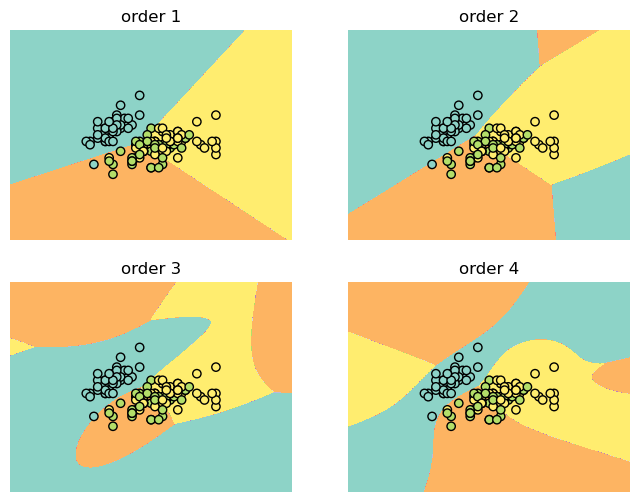

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def model(X,w, deg):
    '''
    model is a function that takes in input X and return the predicted class based on the trained w
    '''
    poly = PolynomialFeatures(deg)
    P = poly.fit_transform(X)
    y_pred = P @ w
    y_pred_class = np.argmax(y_pred, axis=1)
    return y_pred_class


iris_dataset = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris_dataset['data'], iris_dataset['target'], test_size=0.2, random_state=1)

fig = plt.figure(figsize=(8,6))
for i in range(1, 5):
    w, acc_train, acc_test = PolyCls(X_train[:, :2], y_train, X_test[:, :2], y_test, n=i)
    print(f'Training accuracy: {acc_train}')
    print(f'Test accuracy: {acc_test}')
    print(f'trained w:\n{w}')

    x_min, x_max = X_train[:, 0].min() - 2, X_train[:, 0].max() + 2
    y_min, y_max = X_train[:, 1].min() - 2, X_train[:, 1].max() + 2
    h=0.01
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                        np.arange(y_min, y_max, h))

    # here "model" is your model's prediction (classification) function
    Z = model(np.c_[xx.ravel(), yy.ravel()], w, i)  # w is the trained weight of your model

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)

    ax = fig.add_subplot(2, 2, i)
    ax.contourf(xx, yy, Z, cmap=plt.cm.Set3)
    ax.set_axis_off()

    # Plot also the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.Set3, edgecolors='k')
    ax.set_title(f'order {i}')